# 05 – Demand Planning

## Objective

This translates historical demand patterns—along with analytical findings derived from exploratory data analysis and forecasting stages—into actionable business insights.

The primary objectives are as follows:

- To identify periods of low, medium, and high demand for bicycles.
- To examine peak demand periods and their operational implications.
- To assess demand variability and potential pressure on capacity.
- To translate analytical findings into considerations for resource planning.
- To define the necessary inputs and assumptions for the subsequent capacity optimization model.

**How can historical demand patterns and forecasting results support better capacity planning and resource allocation within a bike-sharing system?**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

data_path = Path("hour.csv")

if not data_path.exists():
    raise FileNotFoundError(
        "hour.csv could not be found. Check the project directory."
    )

df = pd.read_csv(data_path)

df["datetime"] = (
    pd.to_datetime(df["dteday"]) +
    pd.to_timedelta(df["hr"], unit="h")
)

df = df.sort_values("datetime").reset_index(drop=True)

print(f"Dataset shape: {df.shape}")
print(f"Date range: {df['datetime'].min()} - {df['datetime'].max()}")

Dataset shape: (17379, 18)
Date range: 2011-01-01 00:00:00 - 2012-12-31 23:00:00


In [2]:
bins = [0, 100, 300, 499, 699, np.inf]

labels = [
    "Very Low",
    "Low",
    "Medium",
    "High",
    "Very High"
]

df["demand_segment"] = pd.cut(
    df["cnt"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

demand_segmentation = (
    df.groupby("demand_segment", observed=False)
    .agg(
        observations=("cnt", "count"),
        average_demand=("cnt", "mean"),
        median_demand=("cnt", "median"),
        minimum_demand=("cnt", "min"),
        maximum_demand=("cnt", "max"),
        demand_std=("cnt", "std")
    )
)

demand_segmentation["share_pct"] = (
    demand_segmentation["observations"] / len(df) * 100
)

display(demand_segmentation.round(2))

,observations,average_demand,median_demand,minimum_demand,maximum_demand,demand_std,share_pct
demand_segment,,,,,,,
Very Low,7035,35.67,27.00,1,100,29.62,40.48
Low,6453,189.46,184.00,101,300,56.21,37.13
Medium,2604,384.61,377.00,301,499,56.96,14.98
High,965,582.22,573.00,500,699,56.01,5.55
Very High,322,794.53,790.50,700,977,66.67,1.85


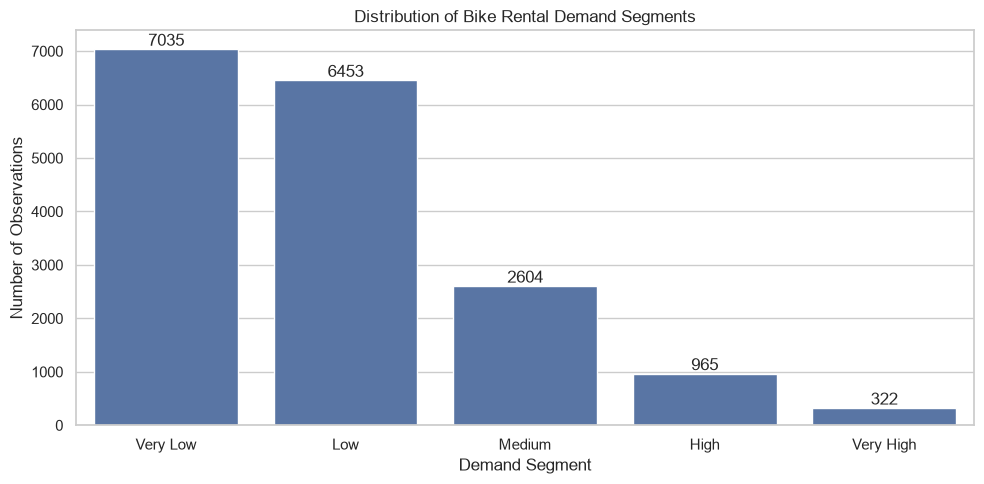

In [3]:
segment_counts = df["demand_segment"].value_counts().reindex(labels)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=segment_counts.index,
    y=segment_counts.values
)

plt.title("Distribution of Bike Rental Demand Segments")
plt.xlabel("Demand Segment")
plt.ylabel("Number of Observations")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.tight_layout()
plt.show()

In [4]:
df["is_high_demand"] = df["cnt"] >= 500

peak_hour_analysis = (
    df.groupby("hr")
    .agg(
        total_observations=("cnt", "count"),
        high_demand_observations=("is_high_demand", "sum"),
        average_demand=("cnt", "mean"),
        maximum_demand=("cnt", "max")
    )
)

peak_hour_analysis["high_demand_rate_pct"] = (
    peak_hour_analysis["high_demand_observations"]
    / peak_hour_analysis["total_observations"] * 100
)

display(
    peak_hour_analysis
    .sort_values("high_demand_rate_pct", ascending=False)
    .round(2)
)

,total_observations,high_demand_observations,average_demand,maximum_demand,high_demand_rate_pct
hr,,,,,
17,730,331,461.45,976,45.34
18,728,271,425.51,977,37.23
8,727,211,359.01,839,29.02
19,728,100,311.52,743,13.74
16,730,74,311.98,783,10.14
14,729,58,240.95,750,7.96
12,728,53,253.32,776,7.28
13,729,53,253.66,760,7.27
15,729,49,251.23,750,6.72


### Peak Demand Analysis

The hourly demand analysis identifies distinct peak-demand periods throughout the day.

The highest concentration of high-demand observations occurs at 17:00, where 45.34% of hourly observations exceed 500 rentals. This is followed by 18:00 (37.23%) and 08:00 (29.02%).

Two demand peaks can therefore be identified:

- **Morning peak:** Around 08:00.
- **Evening peak:** 17:00 - 18:00.

High-demand observations become increasingly rare during nighttime and early morning hours.

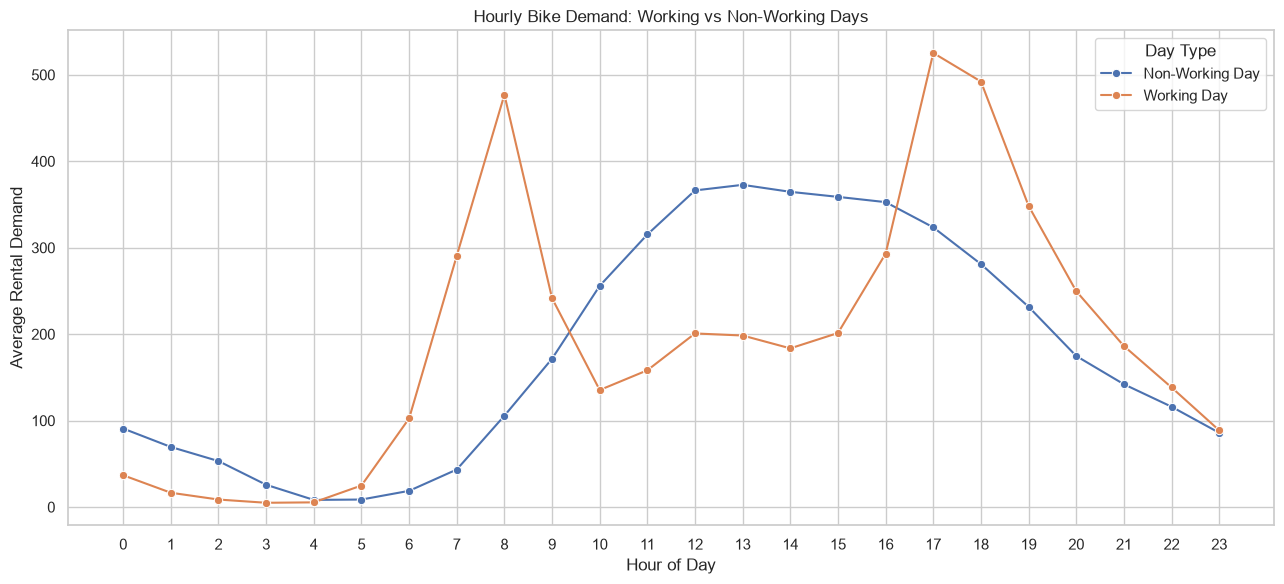

,day_type,hr,observations,high_demand_count,average_demand,high_demand_rate_pct
8,Non-Working Day,8,231,2,105.65,0.87
10,Non-Working Day,10,231,1,255.91,0.43
11,Non-Working Day,11,231,34,315.32,14.72
12,Non-Working Day,12,231,53,366.26,22.94
13,Non-Working Day,13,231,53,372.73,22.94
14,Non-Working Day,14,231,57,364.65,24.68
15,Non-Working Day,15,231,46,358.81,19.91
16,Non-Working Day,16,231,49,352.73,21.21
17,Non-Working Day,17,231,43,323.55,18.61
18,Non-Working Day,18,230,20,281.06,8.70


In [5]:
df["day_type"] = np.where(
    df["workingday"] == 1,
    "Working Day",
    "Non-Working Day"
)

peak_day_analysis = (
    df.groupby(["day_type", "hr"])
    .agg(
        observations=("cnt", "count"),
        high_demand_count=("is_high_demand", "sum"),
        average_demand=("cnt", "mean")
    )
    .reset_index()
)

peak_day_analysis["high_demand_rate_pct"] = (
    peak_day_analysis["high_demand_count"]
    / peak_day_analysis["observations"] * 100
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=peak_day_analysis,
    x="hr",
    y="average_demand",
    hue="day_type",
    marker="o"
)

plt.title("Hourly Bike Demand: Working vs Non-Working Days")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rental Demand")
plt.xticks(range(24))
plt.legend(title="Day Type")
plt.tight_layout()
plt.show()

display(
    peak_day_analysis[
        peak_day_analysis["high_demand_rate_pct"] > 0
    ].round(2)
)

### Working Day vs. Non-Working Day Patterns

On working days, demand is strongly concentrated around commuting hours. The highest demand frequency occurs at 17:00 (57.72%), followed by 18:00 (50.40%) and 08:00 (42.14%).

In contrast, non-working days exhibit a more distributed demand pattern, with the strongest concentration between 12:00 and 16:00. The highest high-demand rate is observed at 14:00 (24.68%).

- **Working days:** Concentrated morning and evening peaks.
- **Non-working days:** Broader midday and afternoon demand.

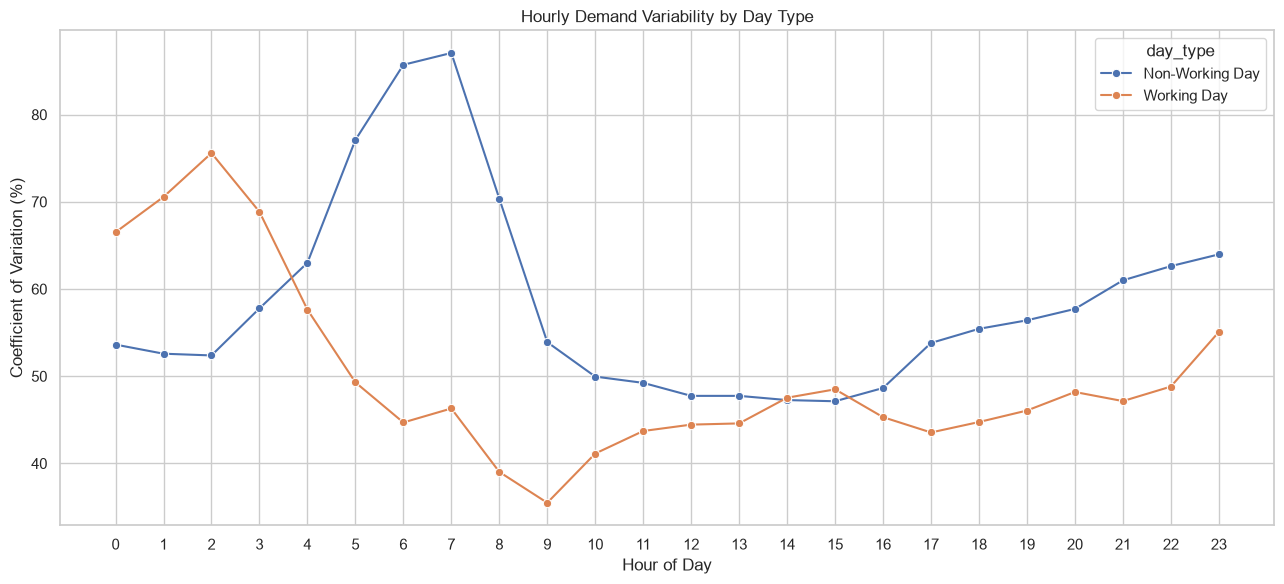

,day_type,hr,observations,mean_demand,std_demand,min_demand,max_demand,cv_pct
7,Non-Working Day,7,231,43.41,37.79,1,387,87.07
6,Non-Working Day,6,229,18.74,16.06,1,133,85.71
5,Non-Working Day,5,222,8.69,6.70,1,55,77.10
26,Working Day,2,487,8.68,6.56,1,74,75.59
25,Working Day,1,494,16.55,11.68,1,114,70.56
8,Non-Working Day,8,231,105.65,74.34,5,597,70.36
27,Working Day,3,470,4.94,3.40,1,36,68.85
24,Working Day,0,496,36.79,24.47,2,283,66.51
23,Non-Working Day,23,230,85.93,54.97,2,239,63.97
28,Working Day,4,470,5.43,3.13,1,17,57.64


In [6]:
demand_variability = (
    df.groupby(["day_type", "hr"])
    .agg(
        observations=("cnt", "count"),
        mean_demand=("cnt", "mean"),
        std_demand=("cnt", "std"),
        min_demand=("cnt", "min"),
        max_demand=("cnt", "max")
    )
    .reset_index()
)

demand_variability["cv_pct"] = (
    demand_variability["std_demand"]
    / demand_variability["mean_demand"] * 100
)

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=demand_variability,
    x="hr",
    y="cv_pct",
    hue="day_type",
    marker="o"
)

plt.title("Hourly Demand Variability by Day Type")
plt.xlabel("Hour of Day")
plt.ylabel("Coefficient of Variation (%)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

display(
    demand_variability
    .sort_values("cv_pct", ascending=False)
    .groupby("day_type")
    .head(5)
    .round(2)
)

### Demand Variability

The coefficient of variation (CV) was used to examine relative demand variability across different hours and day types.

The results show that some low-demand hours have relatively high CV values. However, high relative variability during these periods does not necessarily indicate significant operational capacity pressure, since their average demand is very low.

In contrast, non-working days at 08:00 show both substantial demand and considerable variability, with an average of 105.65 and a standard deviation of 74.34.

In [7]:
df["time_period"] = pd.cut(
    df["hr"],
    bins=[-1, 6, 10, 15, 19, 23],
    labels=[
        "Night / Early Morning",
        "Morning Peak",
        "Midday",
        "Evening Peak",
        "Late Evening"
    ]
)

optimization_inputs = (
    df.groupby(["day_type", "time_period"], observed=True)
    .agg(
        observations=("cnt", "count"),
        average_demand=("cnt", "mean"),
        demand_std=("cnt", "std"),
        peak_demand=("cnt", "max"),
        high_demand_rate=("is_high_demand", "mean")
    )
    .reset_index()
)

optimization_inputs["high_demand_rate_pct"] = (
    optimization_inputs["high_demand_rate"] * 100
)

optimization_inputs = optimization_inputs.drop(
    columns="high_demand_rate"
)

display(optimization_inputs.round(2))


optimization_inputs["peak_to_average_ratio"] = (
    optimization_inputs["peak_demand"]
    / optimization_inputs["average_demand"]
)

optimization_inputs["variability_ratio"] = (
    optimization_inputs["demand_std"]
    / optimization_inputs["average_demand"]
)

demand_pressure_analysis = (
    optimization_inputs[
        [
            "day_type",
            "time_period",
            "average_demand",
            "demand_std",
            "peak_demand",
            "high_demand_rate_pct",
            "peak_to_average_ratio",
            "variability_ratio"
        ]
    ]
    .sort_values(
        "peak_to_average_ratio",
        ascending=False
    )
    .reset_index(drop=True)
)

display(demand_pressure_analysis.round(2))

,day_type,time_period,observations,average_demand,demand_std,peak_demand,high_demand_rate_pct
0,Non-Working Day,Night / Early Morning,1593,39.51,40.25,249,0.00
1,Non-Working Day,Morning Peak,924,144.15,119.01,597,0.32
2,Non-Working Day,Midday,1155,355.55,171.04,776,21.04
3,Non-Working Day,Evening Peak,922,297.34,165.20,783,12.47
4,Non-Working Day,Late Evening,920,129.70,86.87,584,0.33
5,Working Day,Night / Early Morning,3408,28.96,38.45,283,0.00
6,Working Day,Morning Peak,1984,286.13,176.29,839,12.60
7,Working Day,Midday,2487,188.50,88.35,651,0.16
8,Working Day,Evening Peak,1994,414.75,213.00,977,33.15
9,Working Day,Late Evening,1992,165.78,104.00,567,0.40


,day_type,time_period,average_demand,demand_std,peak_demand,high_demand_rate_pct,peak_to_average_ratio,variability_ratio
0,Working Day,Night / Early Morning,28.96,38.45,283,0.00,9.77,1.33
1,Non-Working Day,Night / Early Morning,39.51,40.25,249,0.00,6.30,1.02
2,Non-Working Day,Late Evening,129.70,86.87,584,0.33,4.50,0.67
3,Non-Working Day,Morning Peak,144.15,119.01,597,0.32,4.14,0.83
4,Working Day,Midday,188.50,88.35,651,0.16,3.45,0.47
5,Working Day,Late Evening,165.78,104.00,567,0.40,3.42,0.63
6,Working Day,Morning Peak,286.13,176.29,839,12.60,2.93,0.62
7,Non-Working Day,Evening Peak,297.34,165.20,783,12.47,2.63,0.56
8,Working Day,Evening Peak,414.75,213.00,977,33.15,2.36,0.51
9,Non-Working Day,Midday,355.55,171.04,776,21.04,2.18,0.48


## Weather Impact Analysis

This analysis examines the relationship between weather conditions and rental demand through the following aspects:

- Distribution of demand according to weather conditions.
- Average and peak demand levels under various weather conditions.
- Probability of observing high demand.
- Interactions between weather conditions, types of days, and operational periods.
- The relationship between continuous weather variables and rental demand.

The objective is to identify weather-dependent demand patterns that may influence operational capacity requirements.

In [8]:
weather_labels = {
    1: "Clear / Few Clouds",
    2: "Mist / Cloudy",
    3: "Light Rain / Snow",
    4: "Heavy Rain / Snow"
}

df["weather_condition"] = df["weathersit"].map(weather_labels)

weather_distribution = (
    df.groupby("weather_condition", observed=True)
    .agg(
        observations=("cnt", "count"),
        average_demand=("cnt", "mean"),
        median_demand=("cnt", "median"),
        std_demand=("cnt", "std"),
        minimum_demand=("cnt", "min"),
        maximum_demand=("cnt", "max")
    )
)

weather_distribution["share_pct"] = (
    weather_distribution["observations"] / len(df) * 100
)

display(weather_distribution.round(2))

,observations,average_demand,median_demand,std_demand,minimum_demand,maximum_demand,share_pct
weather_condition,,,,,,,
Clear / Few Clouds,11413,204.87,159.00,189.49,1,977,65.67
Heavy Rain / Snow,3,74.33,36.00,77.93,23,164,0.02
Light Rain / Snow,1419,111.58,63.00,133.78,1,891,8.17
Mist / Cloudy,4544,175.17,133.00,165.43,1,957,26.15


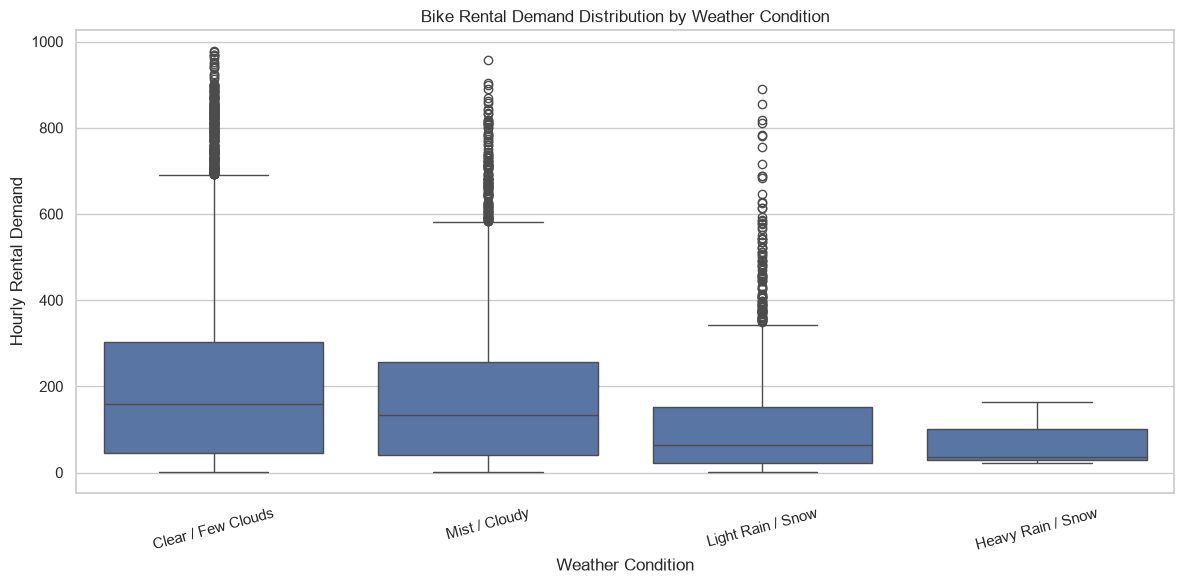

,observations,high_demand_observations,average_demand,maximum_demand,high_demand_probability_pct
weather_condition,,,,,
Clear / Few Clouds,11413,1011,204.87,977,8.86
Mist / Cloudy,4544,239,175.17,957,5.26
Light Rain / Snow,1419,37,111.58,891,2.61
Heavy Rain / Snow,3,0,74.33,164,0.00


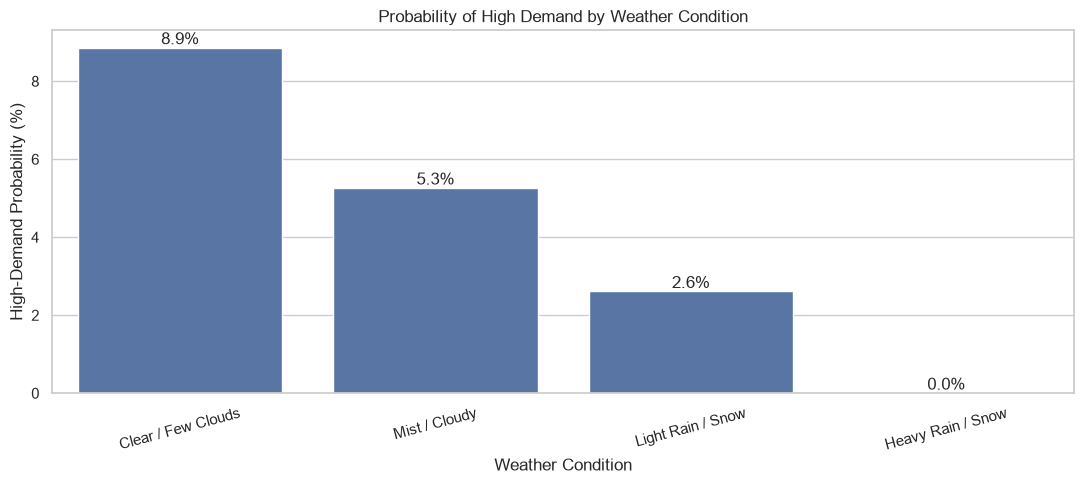

In [9]:
weather_order = [
    "Clear / Few Clouds",
    "Mist / Cloudy",
    "Light Rain / Snow",
    "Heavy Rain / Snow"
]

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="weather_condition",
    y="cnt",
    order=weather_order
)

plt.title("Bike Rental Demand Distribution by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Hourly Rental Demand")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


weather_high_demand = (
    df.groupby("weather_condition", observed=True)
    .agg(
        observations=("cnt", "count"),
        high_demand_observations=("is_high_demand", "sum"),
        average_demand=("cnt", "mean"),
        maximum_demand=("cnt", "max")
    )
)

weather_high_demand["high_demand_probability_pct"] = (
    weather_high_demand["high_demand_observations"]
    / weather_high_demand["observations"] * 100
)

weather_high_demand = weather_high_demand.sort_values(
    "high_demand_probability_pct",
    ascending=False
)

display(weather_high_demand.round(2))


plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=weather_high_demand.reset_index(),
    x="weather_condition",
    y="high_demand_probability_pct",
    order=weather_high_demand.index
)

plt.title("Probability of High Demand by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("High-Demand Probability (%)")
plt.xticks(rotation=15)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.tight_layout()
plt.show()


In [10]:
weather_period_analysis = (
    df.groupby(
        ["weather_condition", "day_type", "time_period"],
        observed=True
    )
    .agg(
        observations=("cnt", "count"),
        average_demand=("cnt", "mean"),
        median_demand=("cnt", "median"),
        std_demand=("cnt", "std"),
        high_demand_rate=("is_high_demand", "mean")
    )
    .reset_index()
)

weather_period_analysis["high_demand_rate_pct"] = (
    weather_period_analysis["high_demand_rate"] * 100
)

display(
    weather_period_analysis
    .drop(columns="high_demand_rate")
    .sort_values(
        ["day_type", "time_period", "average_demand"],
        ascending=[True, True, False]
    )
    .round(2)
)


,weather_condition,day_type,time_period,observations,average_demand,median_demand,std_demand,high_demand_rate_pct
0,Clear / Few Clouds,Non-Working Day,Night / Early Morning,1058,41.76,25.00,42.03,0.00
22,Mist / Cloudy,Non-Working Day,Night / Early Morning,451,36.93,21.00,37.12,0.00
12,Light Rain / Snow,Non-Working Day,Night / Early Morning,83,25.08,16.00,28.26,0.00
10,Heavy Rain / Snow,Non-Working Day,Night / Early Morning,1,23.00,23.00,NaN,0.00
1,Clear / Few Clouds,Non-Working Day,Morning Peak,634,155.82,122.00,122.34,0.32
23,Mist / Cloudy,Non-Working Day,Morning Peak,239,131.86,98.00,110.66,0.42
13,Light Rain / Snow,Non-Working Day,Morning Peak,51,56.61,36.00,58.57,0.00
2,Clear / Few Clouds,Non-Working Day,Midday,821,382.23,374.00,168.42,24.97
24,Mist / Cloudy,Non-Working Day,Midday,256,315.10,314.00,148.31,12.50
14,Light Rain / Snow,Non-Working Day,Midday,78,207.54,167.50,168.27,7.69


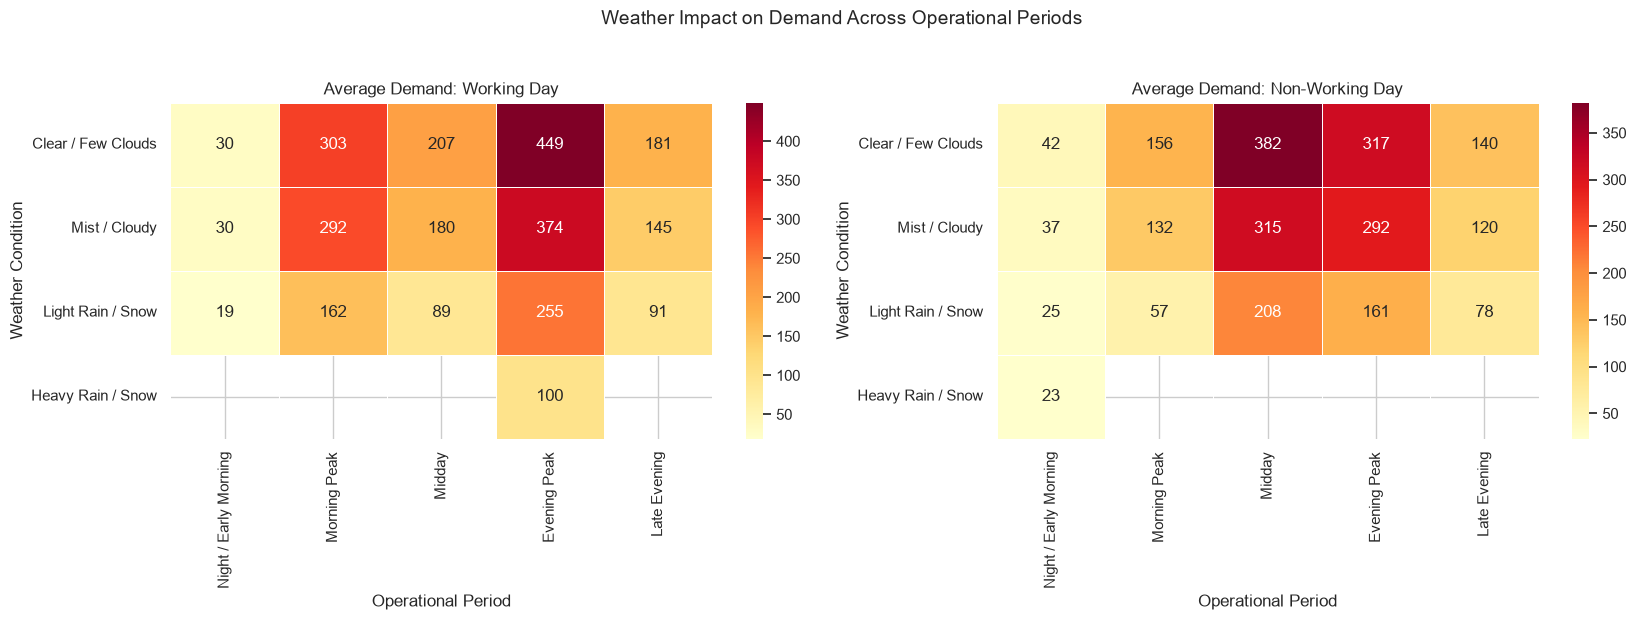

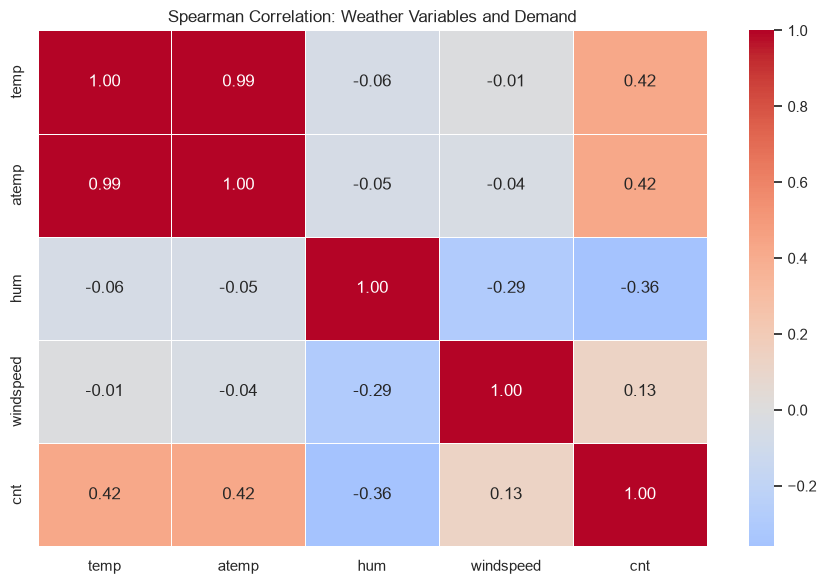

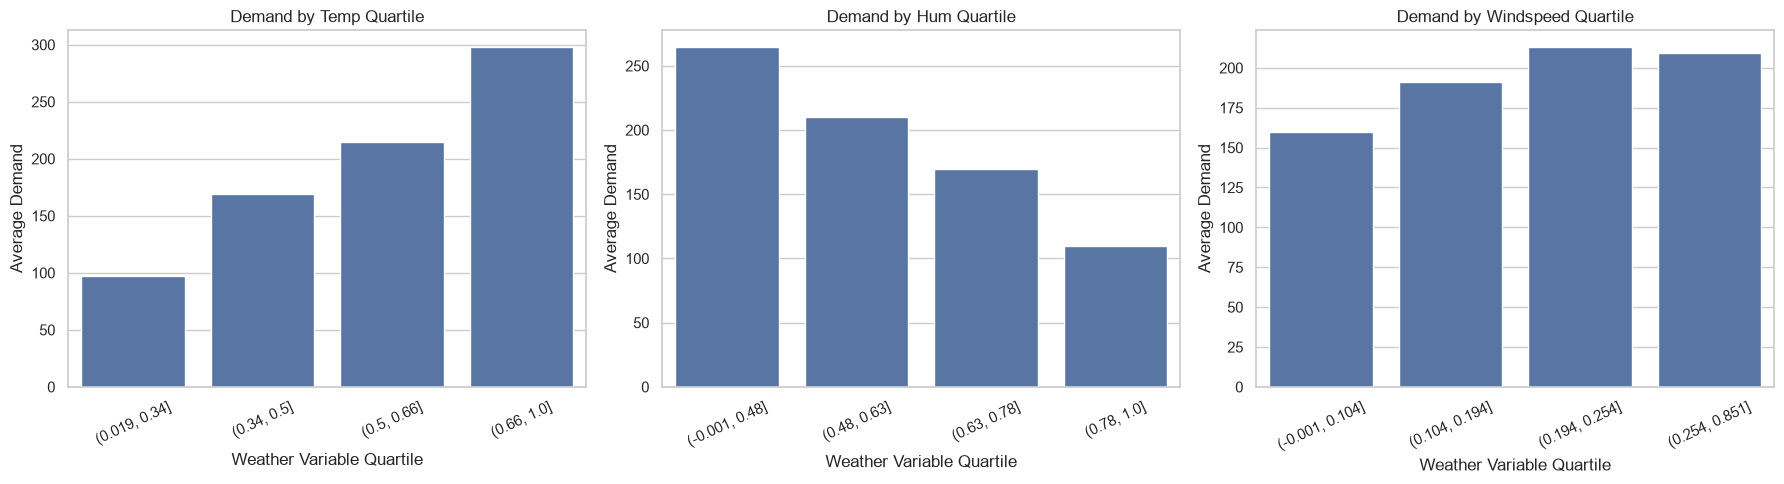

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

for ax, day in zip(
    axes,
    ["Working Day", "Non-Working Day"]
):
    subset = weather_period_analysis[
        weather_period_analysis["day_type"] == day
    ]

    pivot_data = subset.pivot(
        index="weather_condition",
        columns="time_period",
        values="average_demand"
    )

    pivot_data = pivot_data.reindex(weather_order)

    sns.heatmap(
        pivot_data,
        annot=True,
        fmt=".0f",
        cmap="YlOrRd",
        linewidths=0.5,
        ax=ax
    )

    ax.set_title(f"Average Demand: {day}")
    ax.set_xlabel("Operational Period")
    ax.set_ylabel("Weather Condition")

plt.suptitle(
    "Weather Impact on Demand Across Operational Periods",
    fontsize=14,
    y=1.03
)

plt.tight_layout()
plt.show()

weather_variables = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "cnt"
]

weather_correlation = df[weather_variables].corr(
    method="spearman"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    weather_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Spearman Correlation: Weather Variables and Demand")
plt.tight_layout()
plt.show()


continuous_weather = ["temp", "hum", "windspeed"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, variable in zip(axes, continuous_weather):

    quartile_col = f"{variable}_quartile"

    df[quartile_col] = pd.qcut(
        df[variable],
        q=4,
        duplicates="drop"
    )

    quartile_analysis = (
        df.groupby(quartile_col, observed=True)
        .agg(
            average_demand=("cnt", "mean"),
            high_demand_rate=("is_high_demand", "mean"),
            observations=("cnt", "count")
        )
        .reset_index()
    )

    quartile_analysis["high_demand_rate_pct"] = (
        quartile_analysis["high_demand_rate"] * 100
    )

    sns.barplot(
        data=quartile_analysis,
        x=quartile_col,
        y="average_demand",
        ax=ax
    )

    ax.set_title(f"Demand by {variable.capitalize()} Quartile")
    ax.set_xlabel("Weather Variable Quartile")
    ax.set_ylabel("Average Demand")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

Total expected observations: 17544
Missing hourly observations: 165
Missing percentage: 0.94%
Remaining missing observations: 0


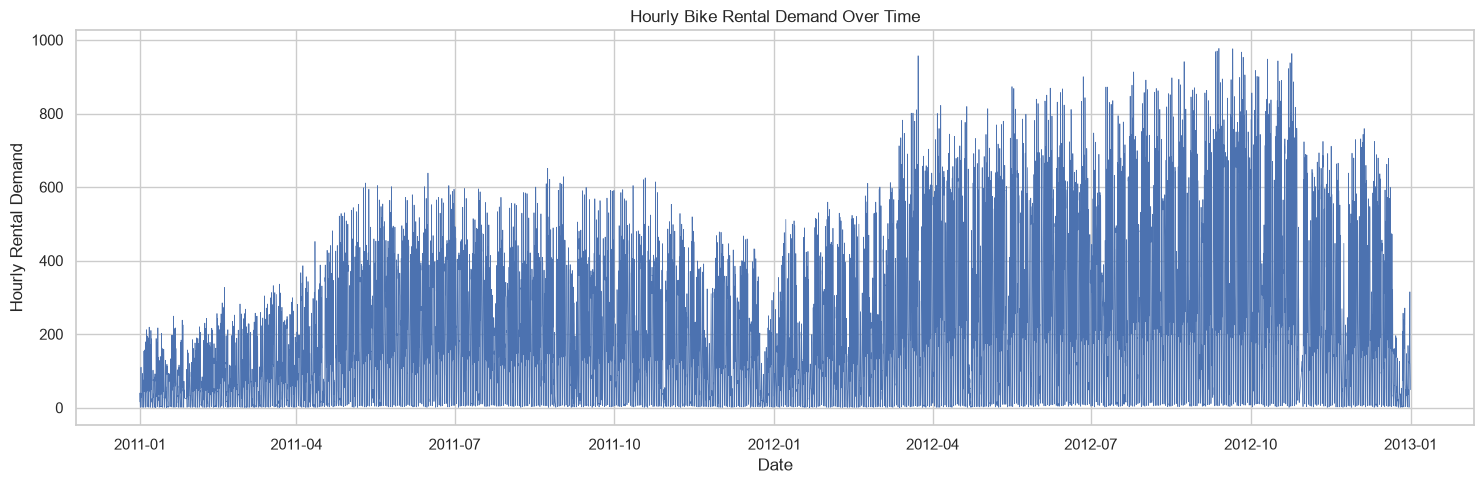

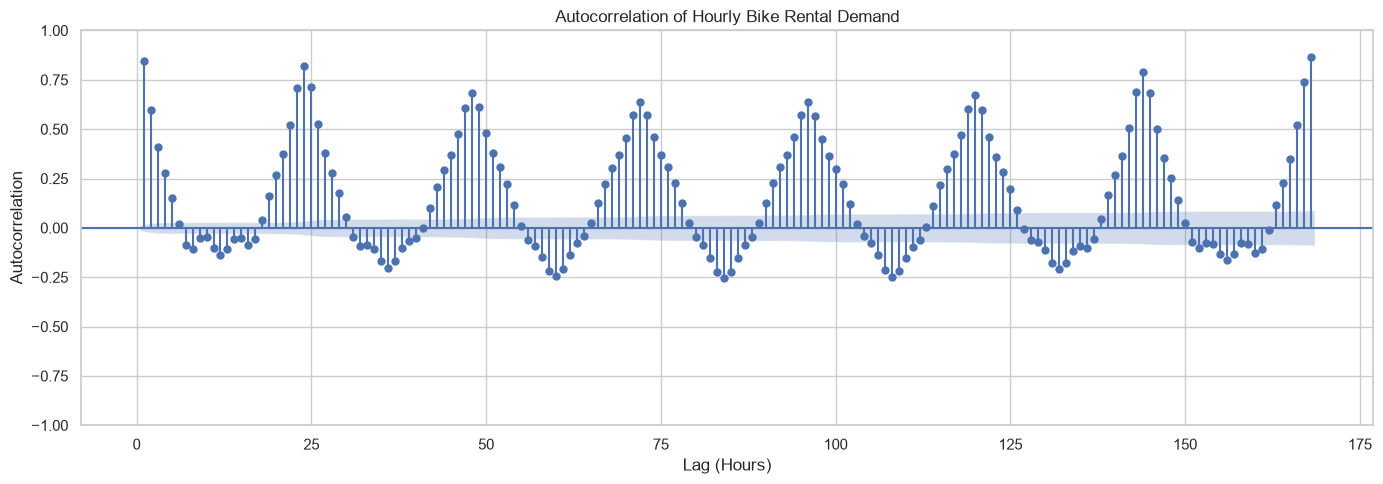

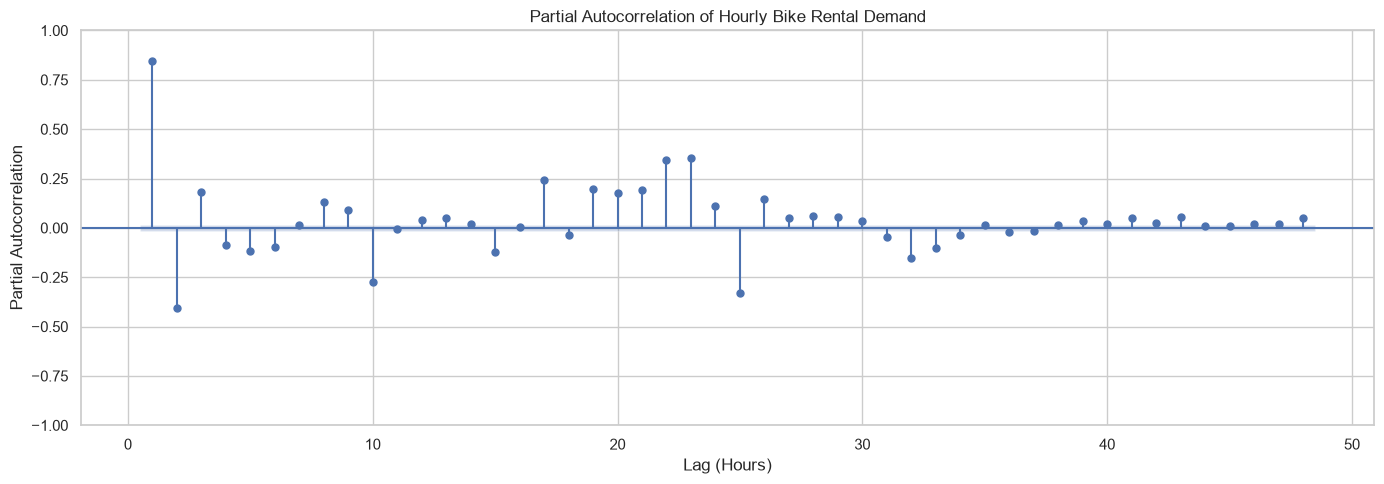

In [15]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import STL

time_series_df = (
    df[["datetime", "cnt"]]
    .sort_values("datetime")
    .drop_duplicates(subset="datetime")
    .copy()
)

time_series = (
    time_series_df
    .set_index("datetime")["cnt"]
    .astype(float)
)

expected_index = pd.date_range(
    start=time_series.index.min(),
    end=time_series.index.max(),
    freq="h"
)

time_series = time_series.reindex(expected_index)
time_series.index.name = "datetime"

missing_count = time_series.isna().sum()

print(f"Total expected observations: {len(time_series)}")
print(f"Missing hourly observations: {missing_count}")
print(f"Missing percentage: {missing_count / len(time_series) * 100:.2f}%")

original_time_series = time_series.copy()

time_series = time_series.interpolate(
    method="time",
    limit_area="inside"
)

print(f"Remaining missing observations: {time_series.isna().sum()}")

if time_series.isna().any():
    raise ValueError("Unresolved missing observations remain.")

plt.figure(figsize=(15, 5))

plt.plot(
    time_series.index,
    time_series.values,
    linewidth=0.5
)

plt.title("Hourly Bike Rental Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Hourly Rental Demand")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))

plot_acf(
    time_series,
    lags=168,
    alpha=0.05,
    ax=ax,
    zero=False
)

ax.set_title("Autocorrelation of Hourly Bike Rental Demand")
ax.set_xlabel("Lag (Hours)")
ax.set_ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 5))

plot_pacf(
    time_series,
    lags=48,
    method="ywm",
    alpha=0.05,
    ax=ax,
    zero=False
)

ax.set_title("Partial Autocorrelation of Hourly Bike Rental Demand")
ax.set_xlabel("Lag (Hours)")
ax.set_ylabel("Partial Autocorrelation")

plt.tight_layout()
plt.show()


,series,adf_statistic,p_value,used_lags,observations,critical_value_1pct,critical_value_5pct,critical_value_10pct,stationary_at_5pct
0,Original Demand,-6.27,0.00,48,17495,-3.43,-2.86,-2.57,True
1,First Difference,-31.83,0.00,48,17494,-3.43,-2.86,-2.57,True
2,24-Hour Seasonal Difference,-22.97,0.00,48,17471,-3.43,-2.86,-2.57,True


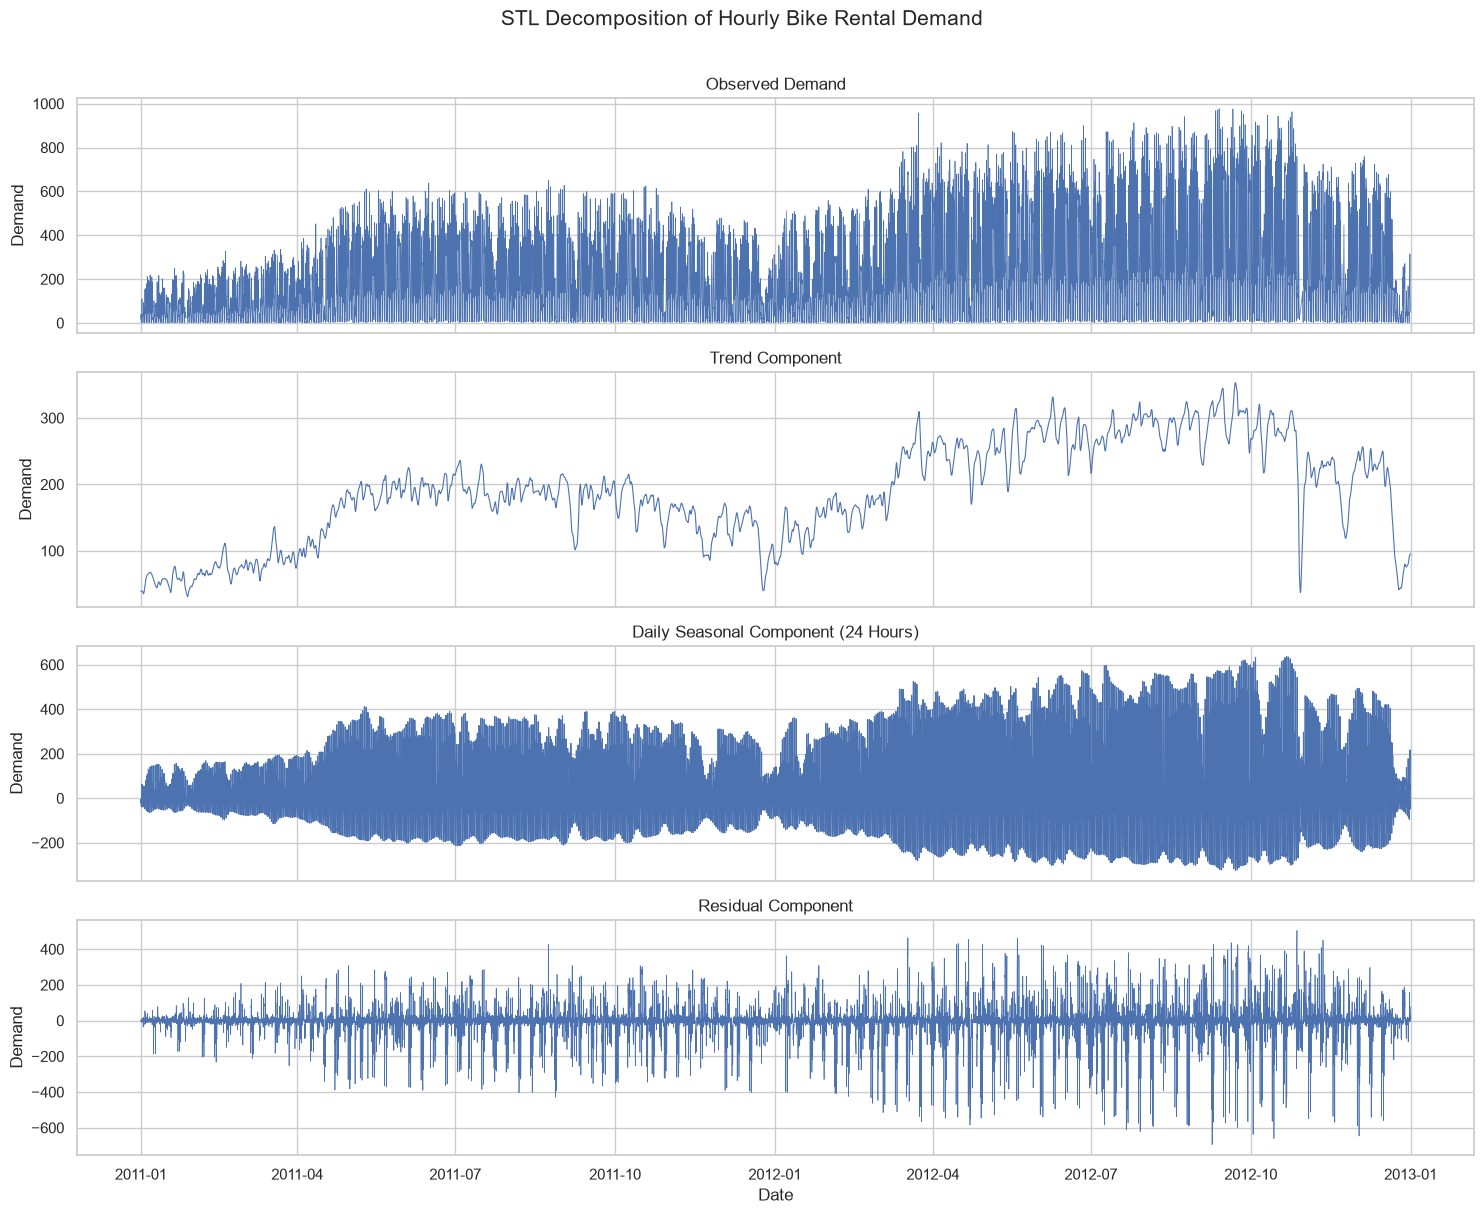

STL Residual Summary


,Residual
count,"17,544.00"
mean,-1.49
std,91.38
min,-694.23
25%,-11.31
50%,-0.42
75%,12.38
max,504.73


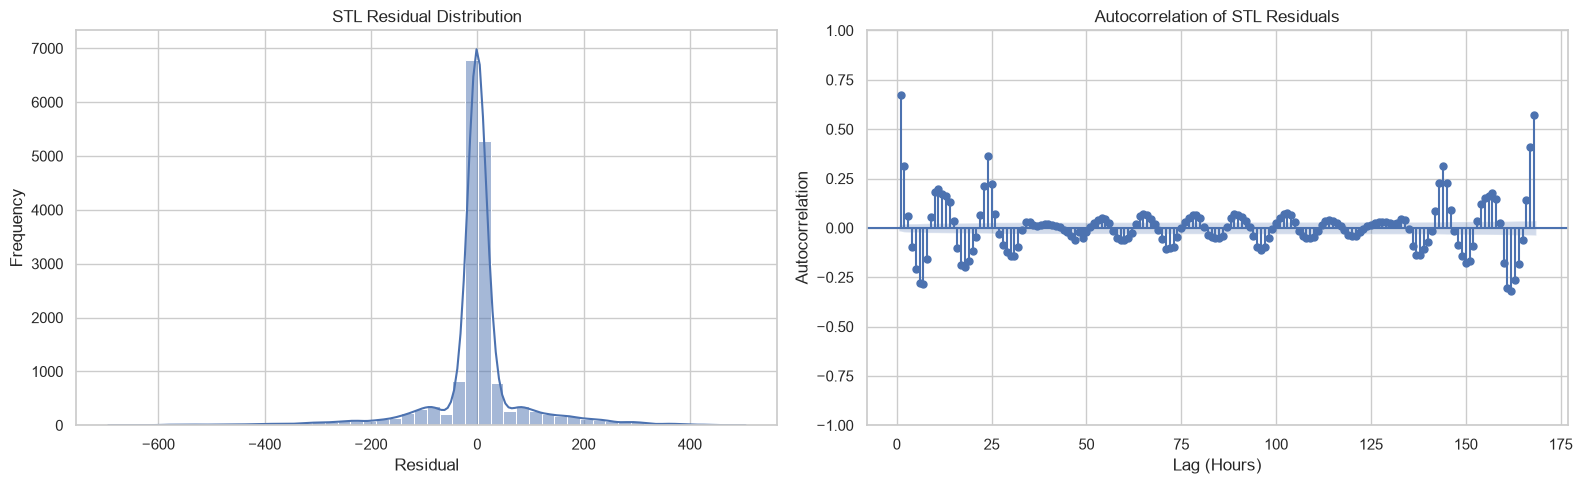

In [21]:
def run_adf_test(series, series_name):

    clean_series = series.dropna()

    result = adfuller(
        clean_series,
        maxlag=48,
        regression="c",
        autolag="AIC",
        result_object=True
    )

    adf_statistic = result.statistic
    p_value = result.pvalue
    critical_value_5pct = result.critical_values["5%"]

    return {
        "series": series_name,
        "adf_statistic": adf_statistic,
        "p_value": p_value,
        "used_lags": result.lags,
        "observations": result.nobs,
        "critical_value_1pct": result.critical_values["1%"],
        "critical_value_5pct": critical_value_5pct,
        "critical_value_10pct": result.critical_values["10%"],
        "stationary_at_5pct": (
            p_value < 0.05
            and adf_statistic < critical_value_5pct
        )
    }

adf_results = []

adf_results.append(
    run_adf_test(
        time_series,
        "Original Demand"
    )
)

adf_results.append(
    run_adf_test(
        time_series.diff(),
        "First Difference"
    )
)

adf_results.append(
    run_adf_test(
        time_series.diff(24),
        "24-Hour Seasonal Difference"
    )
)

adf_results_df = pd.DataFrame(adf_results)

display(adf_results_df.round(4))


stl_model = STL(
    time_series,
    period=24,
    robust=True
)

stl_result = stl_model.fit()

fig, axes = plt.subplots(
    4,
    1,
    figsize=(15, 12),
    sharex=True
)

axes[0].plot(
    time_series.index,
    time_series.values,
    linewidth=0.5
)
axes[0].set_title("Observed Demand")

axes[1].plot(
    time_series.index,
    stl_result.trend,
    linewidth=0.8
)
axes[1].set_title("Trend Component")

axes[2].plot(
    time_series.index,
    stl_result.seasonal,
    linewidth=0.8
)
axes[2].set_title("Daily Seasonal Component (24 Hours)")

axes[3].plot(
    time_series.index,
    stl_result.resid,
    linewidth=0.5
)
axes[3].set_title("Residual Component")

for ax in axes:
    ax.set_ylabel("Demand")

axes[-1].set_xlabel("Date")

plt.suptitle(
    "STL Decomposition of Hourly Bike Rental Demand",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()


residuals = pd.Series(
    stl_result.resid,
    index=time_series.index
)

print("STL Residual Summary")
display(
    residuals.describe().to_frame("Residual").round(3)
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5)
)

sns.histplot(
    residuals,
    bins=50,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("STL Residual Distribution")
axes[0].set_xlabel("Residual")
axes[0].set_ylabel("Frequency")

plot_acf(
    residuals,
    lags=168,
    alpha=0.05,
    ax=axes[1],
    zero=False
)

axes[1].set_title(
    "Autocorrelation of STL Residuals"
)
axes[1].set_xlabel("Lag (Hours)")
axes[1].set_ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

## Implications for Capacity Planning

The analysis identified distinct demand patterns that emerge between workdays and non-workdays, across different time periods, and under the influence of weather conditions.

The planning considerations are:

- **Temporal Demand Patterns:** Workdays and non-workdays exhibit distinct peak demand structures, necessitating capacity allocation that varies over time.
- **Demand Variability:** Average demand alone may not adequately represent operational requirements; demand variability and the likelihood of high-demand scenarios must also be considered.
- **Sensitivity to Weather Conditions:** Weather conditions introduce additional uncertainty and can alter the intensity of demand throughout operational periods.
- **Temporal Dependence:** Autocorrelation and seasonal patterns indicate that hourly demand observations are not necessarily independent. This dependence must be accounted for in demand simulations and stress testing.
- **Uncertainty-Aware Capacity Planning:** Rather than relying solely on historical averages, capacity decisions should factor in both expected demand and adverse demand scenarios.

The findings indicate that a uniform capacity allocation strategy may not adequately reflect actual demand patterns.

A more responsive planning approach should take the following into account:

1. Differences between business days and non-business days.
2. Time-dependent demand fluctuations.
3. Average demand and demand variability.
4. The frequency and magnitude of peak demand periods.